In [ ]:
# Import libraries
import json
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import train_test_split

In [ ]:

# Environment and Dataset Verification

import sys
import importlib.util
from pathlib import Path


print("=" * 50)
print("PYTHON ENVIRONMENT")
print("=" * 50)

print("Python version:", sys.version)
print("Python executable:", sys.executable)


packages = ["tensorflow", "numpy", "matplotlib", "sklearn", "PIL"]

print("\nPACKAGE INSTALLATION STATUS")

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    status = "Installed" if installed else "Not installed"
    print(f"{package}: {status}")


DATASET_DIR = Path(r"C:\plantvillage dataset\color")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

print("\n" + "=" * 50)
print("PLANTVILLAGE DATASET")
print("=" * 50)

if not DATASET_DIR.is_dir():
    print("Dataset folder not found!")
    print("Expected location:", DATASET_DIR)
    print("Please check where your dataset was extracted.")

else:
    class_folders = sorted(
        folder for folder in DATASET_DIR.iterdir()
        if folder.is_dir()
    )

    print("Dataset path:", DATASET_DIR)
    print("Number of classes:", len(class_folders))

    total_images = 0
    class_counts = {}

    for folder in class_folders:
        image_count = sum(
            1 for file in folder.rglob("*")
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        class_counts[folder.name] = image_count
        total_images += image_count

    print("\nIMAGE COUNT BY CLASS")

    for class_name, count in class_counts.items():
        print(f"{class_name}: {count}")

    print("\nTotal images:", total_images)

    empty_classes = [
        name for name, count in class_counts.items()
        if count == 0
    ]

    print("Classes with no images:", empty_classes)


PYTHON ENVIRONMENT
Python version: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Users\nbora\AppData\Local\Programs\Python\Python313\python.exe

PACKAGE INSTALLATION STATUS
tensorflow: Installed
numpy: Installed
matplotlib: Installed
sklearn: Installed
PIL: Installed

PLANTVILLAGE DATASET
Dataset path: C:\plantvillage dataset\color
Number of classes: 38

IMAGE COUNT BY CLASS
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___healthy: 854
Cherry_(including_sour)___Powdery_mildew: 1052
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___healthy: 1162
Corn_(maize)___Northern_Leaf_Blight: 985
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___healthy: 423
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacteria

In [ ]:
 
#  Divide the dataset into training, validation and testing

import csv
import json
from pathlib import Path
from sklearn.model_selection import train_test_split


DATASET_DIR = Path(r"C:\plantvillage dataset\color")
PROJECT_DIR = Path(r"C:\PlantDiseaseProject")
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

image_types = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


image_paths = []
labels = []

for folder in sorted(DATASET_DIR.iterdir()):
    if folder.is_dir():
        for image in sorted(folder.rglob("*")):
            if image.is_file() and image.suffix.lower() in image_types:
                image_paths.append(str(image.resolve()))
                labels.append(folder.name)

print("Total images:", len(image_paths))
print("Total classes:", len(set(labels)))


train_paths, remaining_paths, train_labels, remaining_labels = train_test_split(
    image_paths,
    labels,test_size=0.30,
    random_state=42,stratify=labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    remaining_paths,
    remaining_labels,test_size=0.50,
    random_state=42,stratify=remaining_labels
)

# Give each class a numerical ID
class_names = sorted(set(labels))
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

# Save the class names and their IDs
with open(RESULTS_DIR / "class_mapping.json", "w", encoding="utf-8") as file:
    json.dump(class_to_index, file, indent=2)


csv_path = RESULTS_DIR / "dataset_split_seed42.csv"

with open(csv_path, "w", newline="", encoding="utf-8-sig") as file:
    writer = csv.writer(file)
    writer.writerow(["image_path", "class_name", "label_id", "split"])

    for paths, class_labels, group in [
        (train_paths, train_labels, "training"),
        (val_paths, val_labels, "validation"),
        (test_paths, test_labels, "testing")
    ]:
        for path, label in zip(paths, class_labels):
            writer.writerow([
                path, label, class_to_index[label], group
            ])


print("\nDataset split completed!")
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

print("\nSaved files:")
print(RESULTS_DIR / "class_mapping.json")
print(csv_path)


Total images: 54305
Total classes: 38

Dataset split completed!
Training images: 38013
Validation images: 8146
Testing images: 8146

Saved files:
C:\PlantDiseaseProject\results\class_mapping.json
C:\PlantDiseaseProject\results\dataset_split_seed42.csv


Images are ready for the CNN!
Training batches: 1187
Validation batches: 254
Testing batches: 254


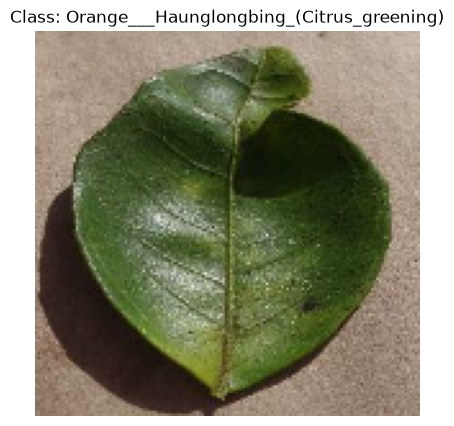

Image shape: (150, 150, 3)
Pixel value range: 0.0 to 0.9569025635719299


In [ ]:

# Load and prepare the images


IMAGE_SIZE = (150, 150)
BATCH_SIZE = 32


def make_dataset(paths, labels, training=False):

 
    label_ids = [class_to_index[label] for label in labels]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, label_ids)
    )

   
    if training:
        dataset = dataset.shuffle(
            buffer_size=5000,
            seed=42
        )

  
    def prepare_image(image_path, label):
        image = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image = tf.image.resize(image, IMAGE_SIZE)
        image = tf.cast(image, tf.float32) / 255.0
        image.set_shape((150, 150, 3))

        return image, label

    dataset = dataset.map(
        prepare_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


train_ds = make_dataset(
    train_paths, train_labels, training=True
)

val_ds = make_dataset(
    val_paths, val_labels
)

test_ds = make_dataset(
    test_paths, test_labels
)

print("Images are ready for the CNN!")
print("Training batches:", len(train_paths) // BATCH_SIZE)
print("Validation batches:", len(val_paths) // BATCH_SIZE)
print("Testing batches:", len(test_paths) // BATCH_SIZE)

# Display one training image
images, labels_batch = next(iter(train_ds))

label_id = int(labels_batch[0].numpy())

plt.figure(figsize=(5, 5))
plt.imshow(images[0].numpy())
plt.title("Class: " + class_names[label_id])
plt.axis("off")
plt.show()

print("Image shape:", images[0].shape)
print("Pixel value range:",
      float(tf.reduce_min(images[0])),
      "to",
      float(tf.reduce_max(images[0])))


In [ ]:

# Build the CNN model

num_classes = len(class_names)


model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)), 
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])
model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])


model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,662 (447.90 KB)

 Trainable params: 114,662 (447.90 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Training the CNN model


PROJECT_DIR = Path(r"C:\PlantDiseaseProject")
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the best model
checkpoint = ModelCheckpoint(
    filepath=str(MODEL_DIR / "best_plant_disease_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[checkpoint, early_stop]
)


model.save(MODEL_DIR / "plant_disease_cnn.keras")

print("\nTraining completed!")
print("Trained model saved in:", MODEL_DIR)


Epoch 1/5


c:\Users\nbora\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - accuracy: 0.3529 - loss: 2.3140
Epoch 1: val_loss improved from None to 1.49370, saving model to C:\PlantDiseaseProject\models\best_plant_disease_model.keras

Epoch 1: finished saving model to C:\PlantDiseaseProject\models\best_plant_disease_model.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 538s 451ms/step - accuracy: 0.3529 - loss: 2.3140 - val_accuracy: 0.5523 - val_loss: 1.4937
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.5840 - loss: 1.4040
Epoch 2: val_loss improved from 1.49370 to 1.04673, saving model to C:\PlantDiseaseProject\models\best_plant_disease_model.keras

Epoch 2: finished saving model to C:\PlantDiseaseProject\models\best_plant_disease_model.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 418s 352ms/step - accuracy: 0.5840 - loss: 1.4040 - val_accuracy: 0.6838 - val_loss: 1.0467
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.6825 - loss: 1.0381
Epoch 3: val_loss improved from 1.04673 to 0.77953

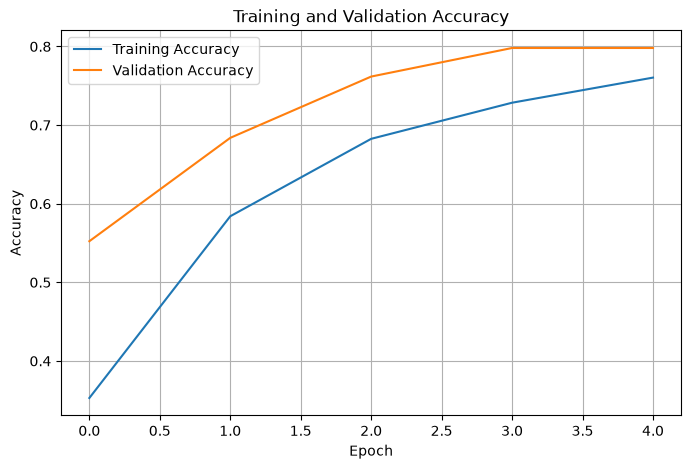

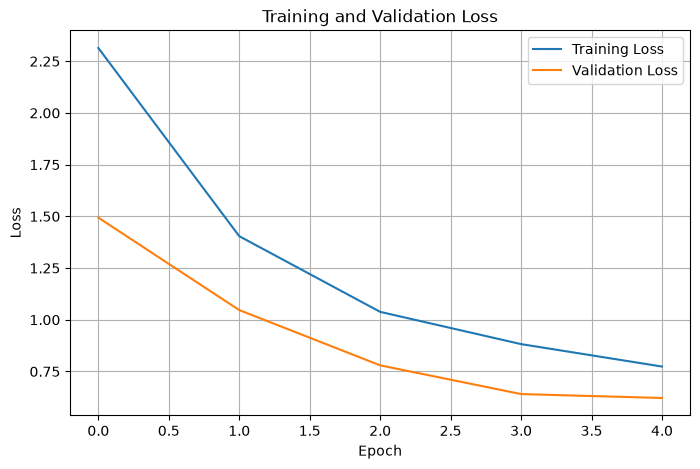

Training graphs saved successfully!


In [ ]:

# Plot training results

RESULTS_DIR = Path(r"C:\PlantDiseaseProject\results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

#   accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULTS_DIR / "training_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULTS_DIR / "training_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Training graphs saved successfully!")


255/255 ━━━━━━━━━━━━━━━━━━━━ 59s 233ms/step

TEST RESULTS
----------------------------------------
Test accuracy: 80.63%

Classification Report
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.723     0.638     0.678        94
                                 Apple___Black_rot      0.662     0.548     0.600        93
                          Apple___Cedar_apple_rust      0.667     0.098     0.170        41
                                   Apple___healthy      0.766     0.772     0.769       246
                               Blueberry___healthy      0.717     0.996     0.833       226
          Cherry_(including_sour)___Powdery_mildew      0.762     0.772     0.767       158
                 Cherry_(including_sour)___healthy      0.706     0.938     0.805       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.750     0.351     0.478        77
                       Corn

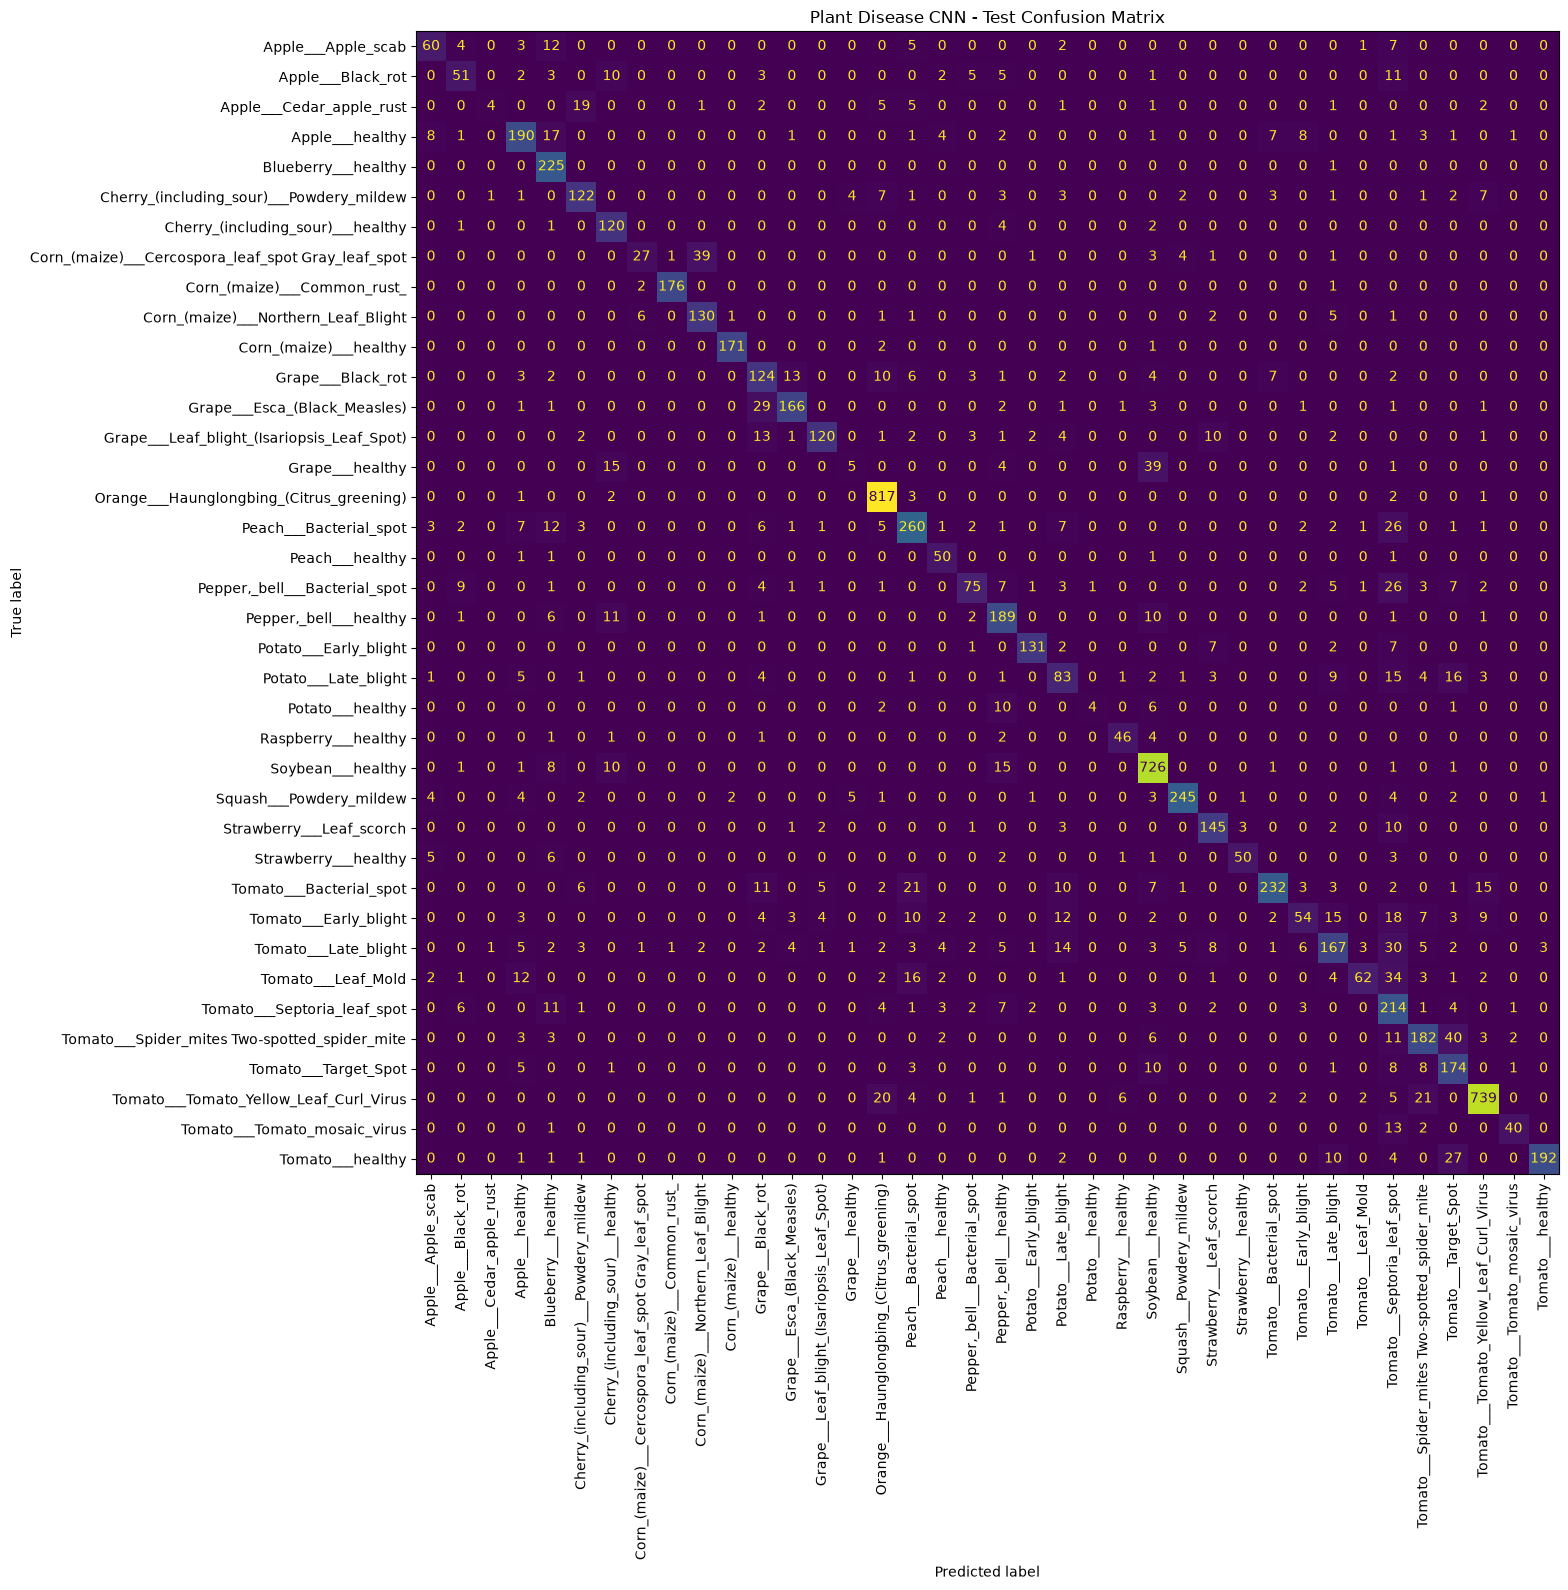


Confusion matrix saved to: C:\PlantDiseaseProject\results


In [ ]:

#Evaluate the model on test images

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
predictions = model.predict(test_ds, verbose=1)

y_pred = np.argmax(predictions, axis=1)

y_true = np.array([
    class_to_index[label] for label in test_labels
])

test_accuracy = accuracy_score(y_true, y_pred)

print("\nTEST RESULTS")
print("-" * 40)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# precision, recall and F1-score
print("\nClassification Report")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=3,
    zero_division=0
))

results_dir = Path(r"C:\PlantDiseaseProject\results")
results_dir.mkdir(parents=True, exist_ok=True)

# confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(18, 16))
display.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)
plt.title("Plant Disease CNN - Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    results_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nConfusion matrix saved to:", results_dir)


In [ ]:

# Training a CNN with data augmentation


data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

model_aug = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_augmentation,
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

# Configure training
model_aug.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_dir = Path(r"C:\PlantDiseaseProject\models")
model_dir.mkdir(parents=True, exist_ok=True)

checkpoint_aug = ModelCheckpoint(
    str(model_dir / "best_plant_disease_augmented.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stop_aug = EarlyStopping(
    monitor="val_loss",
    patience=2
    restore_best_weights=True
)

history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[checkpoint_aug, early_stop_aug]
)

model_aug.save(
    model_dir / "plant_disease_cnn_augmented.keras"
)

print("Experiment 2 training completed!")


Epoch 1/5


c:\Users\nbora\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.3233 - loss: 2.4721
Epoch 1: val_loss improved from None to 1.58710, saving model to C:\PlantDiseaseProject\models\best_plant_disease_augmented.keras

Epoch 1: finished saving model to C:\PlantDiseaseProject\models\best_plant_disease_augmented.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 549s 460ms/step - accuracy: 0.3233 - loss: 2.4721 - val_accuracy: 0.5319 - val_loss: 1.5871
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.5389 - loss: 1.5305
Epoch 2: val_loss improved from 1.58710 to 1.44329, saving model to C:\PlantDiseaseProject\models\best_plant_disease_augmented.keras

Epoch 2: finished saving model to C:\PlantDiseaseProject\models\best_plant_disease_augmented.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 516s 434ms/step - accuracy: 0.5389 - loss: 1.5305 - val_accuracy: 0.5583 - val_loss: 1.4433
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.6424 - loss: 1.1639
Epoch 3: val_loss improved from 1.

255/255 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step

EXPERIMENT 2: CNN WITH DATA AUGMENTATION
---------------------------------------------
Test accuracy: 76.45%
Macro precision: 72.86%
Macro recall: 68.34%
Macro F1-score: 68.75%
Weighted F1-score: 76.06%

Classification report by class:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.786     0.351     0.485        94
                                 Apple___Black_rot      0.765     0.559     0.646        93
                          Apple___Cedar_apple_rust      0.750     0.146     0.245        41
                                   Apple___healthy      0.806     0.691     0.744       246
                               Blueberry___healthy      0.934     0.810     0.867       226
          Cherry_(including_sour)___Powdery_mildew      0.703     0.646     0.673       158
                 Cherry_(including_sour)___healthy      0.960     0.750    

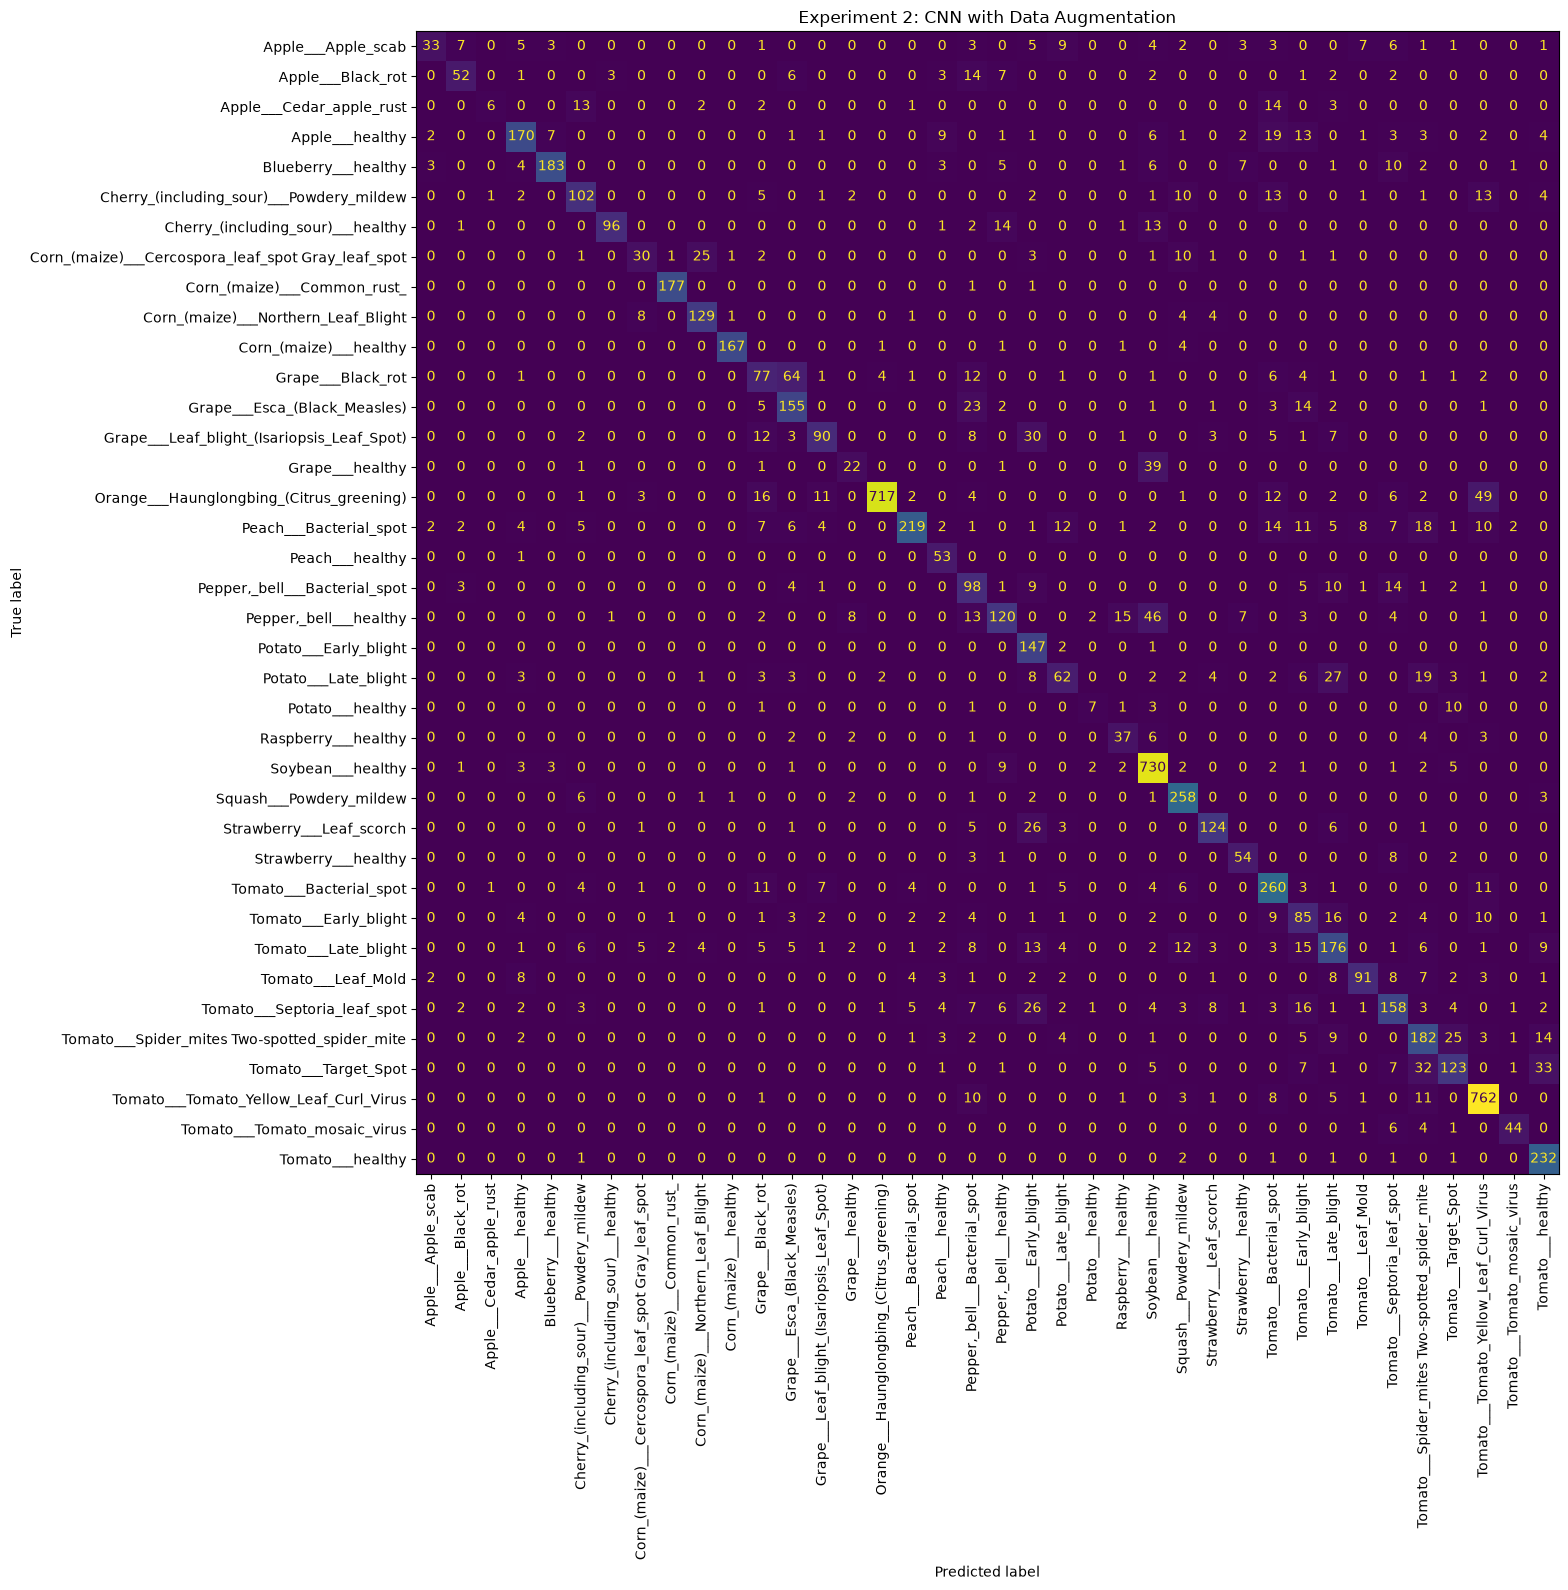


Results saved to: C:\PlantDiseaseProject\results\experiment2_metrics.json
Confusion matrix saved to: C:\PlantDiseaseProject\results


In [ ]:

# Step 9: Evaluate the augmented CNN

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
results_dir = Path(r"C:\PlantDiseaseProject\results")
results_dir.mkdir(parents=True, exist_ok=True)

predictions_aug = model_aug.predict(test_ds, verbose=1)

y_pred_aug = np.argmax(predictions_aug, axis=1)

y_true = np.array([
    class_to_index[label] for label in test_labels
])

accuracy_aug = accuracy_score(y_true, y_pred_aug)

report = classification_report(
    y_true,
    y_pred_aug,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print("\nEXPERIMENT 2: CNN WITH DATA AUGMENTATION")
print("-" * 45)
print(f"Test accuracy: {accuracy_aug * 100:.2f}%")
print(f"Macro precision: {report['macro avg']['precision'] * 100:.2f}%")
print(f"Macro recall: {report['macro avg']['recall'] * 100:.2f}%")
print(f"Macro F1-score: {report['macro avg']['f1-score'] * 100:.2f}%")
print(f"Weighted F1-score: {report['weighted avg']['f1-score'] * 100:.2f}%")

# Display results for individual classes
print("\nClassification report by class:")

print(classification_report(
    y_true,
    y_pred_aug,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=3,
    zero_division=0
))

metrics = {
    "experiment": "CNN with data augmentation",
    "test_accuracy": float(accuracy_aug),
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1_score": report["macro avg"]["f1-score"],
    "weighted_f1_score": report["weighted avg"]["f1-score"],
    "test_images": len(y_true),
    "number_of_classes": len(class_names)
}

metrics_path = results_dir / "experiment2_metrics.json"

with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

cm_aug = confusion_matrix(
    y_true,
    y_pred_aug,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(18, 16))

ConfusionMatrixDisplay(
    confusion_matrix=cm_aug,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

plt.title("Experiment 2: CNN with Data Augmentation")
plt.tight_layout()

plt.savefig(
    results_dir / "confusion_matrix_augmented.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nResults saved to:", metrics_path)
print("Confusion matrix saved to:", results_dir)


MODEL COMPARISON
---------------------------------------------------------------------------

 CNN without augmentation
Accuracy: 80.63%
Macro Precision: 77.80%
Macro Recall: 71.30%
Macro F1-score: 72.10%
Weighted F1-score: 80.00%

 CNN with augmentation
Accuracy: 76.45%
Macro Precision: 72.86%
Macro Recall: 68.34%
Macro F1-score: 68.75%
Weighted F1-score: 76.06%

Comparison saved to: C:\PlantDiseaseProject\results\model_comparison.csv


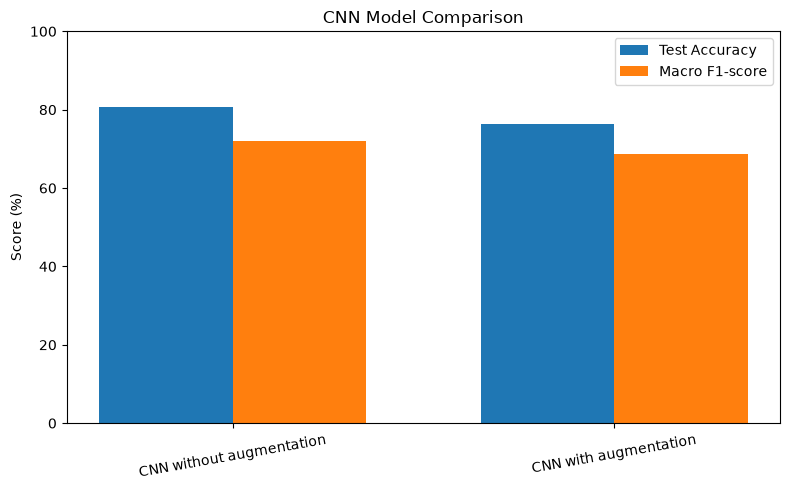

Comparison graph saved successfully!


In [ ]:

# Compare the two CNN experiments

import csv

results_dir = Path(r"C:\PlantDiseaseProject\results")
results_dir.mkdir(parents=True, exist_ok=True)
results = [
    {
        "Model": "CNN without augmentation",
        "Accuracy": 80.63,
        "Macro Precision": 77.80,
        "Macro Recall": 71.30,
        "Macro F1-score": 72.10,
        "Weighted F1-score": 80.00
    },
    {
        "Model": "CNN with augmentation",
        "Accuracy": 76.45,
        "Macro Precision": 72.86,
        "Macro Recall": 68.34,
        "Macro F1-score": 68.75,
        "Weighted F1-score": 76.06
    }
]

# Displaying   the comparison
print("MODEL COMPARISON")
print("-" * 75)

for result in results:
    print("\n", result["Model"])
    for metric, value in result.items():
        if metric != "Model":
            print(f"{metric}: {value:.2f}%")

csv_path = results_dir / "model_comparison.csv"

with csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

print("\nComparison saved to:", csv_path)

models = [result["Model"] for result in results]
accuracies = [result["Accuracy"] for result in results]
macro_f1 = [result["Macro F1-score"] for result in results]

x = [0, 1]
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    [i - width / 2 for i in x],
    accuracies,
    width,
    label="Test Accuracy"
)

plt.bar(
    [i + width / 2 for i in x],
    macro_f1,
    width,
    label="Macro F1-score"
)

plt.xticks(x, models, rotation=10)
plt.ylabel("Score (%)")
plt.title("CNN Model Comparison")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig(
    results_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison graph saved successfully!")


FIRST MODEL - NEW PHOTO
----------------------------------------
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 68.49%
Pepper,_bell___Bacterial_spot: 15.05%
Grape___Black_rot: 13.32%


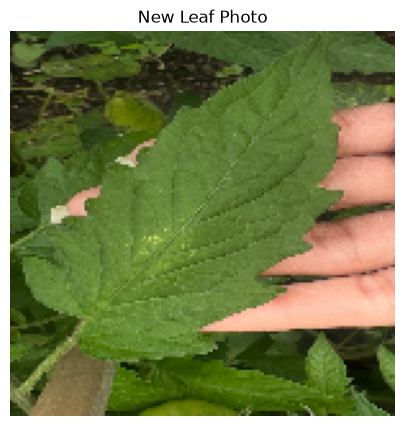

In [ ]:

# Test the first CNN on a new leaf photo

PROJECT_DIR = Path(r"C:\PlantDiseaseProject")


IMAGE_PATH = PROJECT_DIR / "test_photos" / "tomato_leaf.jpeg"

MODEL_PATH = PROJECT_DIR / "models" / "plant_disease_cnn.keras"

if not IMAGE_PATH.is_file():
    print("Photo not found:", IMAGE_PATH)
    print("Check the image name and folder.")
else:

    model = tf.keras.models.load_model(MODEL_PATH)

    # Load the class names in the correct order
    with open(
        PROJECT_DIR / "results" / "class_mapping.json",
        "r",
        encoding="utf-8"
    ) as file:
        class_to_index = json.load(file)

    class_names = [
        name for name, index in sorted(
            class_to_index.items(),
            key=lambda item: item[1]
        )
    ]

    # Resize and prepare the image
    image = tf.keras.utils.load_img(
        IMAGE_PATH,
        target_size=(150, 150)
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]

    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("FIRST MODEL - NEW PHOTO")
    print("-" * 40)

    for index in top_indices:
        print(
            f"{class_names[index]}: "
            f"{probabilities[index] * 100:.2f}%"
        )

    # Show the photo
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title("New Leaf Photo")
    plt.axis("off")
    plt.show()


In [ ]:

# Test the augmented model on the same tomato leaf photo

project_dir = Path(r"C:\PlantDiseaseProject")

image_path = project_dir / "test_photos" / "tomato_leaf.jpeg"
model_path = project_dir / "models" / "plant_disease_cnn_augmented.keras"
mapping_path = project_dir / "results" / "class_mapping.json"

if not image_path.is_file():
    print("Image not found:", image_path)

else:

    augmented_model = tf.keras.models.load_model(model_path)

    # Load the class
    with open(mapping_path, "r", encoding="utf-8") as file:
        class_to_index = json.load(file)

    class_names = [
        name for name, index in sorted(
            class_to_index.items(),
            key=lambda item: item[1]
        )
    ]

    image = tf.keras.utils.load_img(
        image_path,
        target_size=(150, 150)
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = augmented_model.predict(
        image_array, verbose=0
    )[0]

    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("AUGMENTED MODEL - NEW PHOTO")
    print("-" * 40)

    for index in top_indices:
        print(
            f"{class_names[index]}: "
            f"{probabilities[index] * 100:.2f}%"
        )


AUGMENTED MODEL - NEW PHOTO
----------------------------------------
Pepper,_bell___Bacterial_spot: 64.63%
Grape___Black_rot: 19.06%
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 7.05%


In [ ]:

# Step 13: Experiment 3 - MobileNetV2


PROJECT_DIR = Path(r"C:\PlantDiseaseProject")
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)


base_model = keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet")
base_model.trainable = False
inputs = keras.Input(shape=(150, 150, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)

x = layers.Rescaling(scale=2.0, offset=-1.0)(x)
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense( num_classes,
    activation="softmax"
)(x)

model_transfer = keras.Model(inputs, outputs)

model_transfer.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_transfer.summary()

checkpoint = ModelCheckpoint(
    MODEL_DIR / "best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)
history_transfer = model_transfer.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[checkpoint, early_stop]
)
model_transfer.save(
    MODEL_DIR / "plant_disease_mobilenetv2.keras"
)

print("Experiment 3 training completed!")


C:\Users\nbora\AppData\Local\Temp\ipykernel_18792\707099905.py:15: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_41"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/8


c:\Users\nbora\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.7904 - loss: 0.7124
Epoch 1: val_loss improved from None to 0.31562, saving model to C:\PlantDiseaseProject\models\best_mobilenetv2.keras

Epoch 1: finished saving model to C:\PlantDiseaseProject\models\best_mobilenetv2.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 361s 300ms/step - accuracy: 0.7904 - loss: 0.7124 - val_accuracy: 0.9028 - val_loss: 0.3156
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.8808 - loss: 0.3798
Epoch 2: val_loss improved from 0.31562 to 0.28472, saving model to C:\PlantDiseaseProject\models\best_mobilenetv2.keras

Epoch 2: finished saving model to C:\PlantDiseaseProject\models\best_mobilenetv2.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 421s 355ms/step - accuracy: 0.8808 - loss: 0.3798 - val_accuracy: 0.9094 - val_loss: 0.2847
Epoch 3/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.8926 - loss: 0.3377
Epoch 3: val_loss did not improve from 0.28472
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 390s

255/255 ━━━━━━━━━━━━━━━━━━━━ 60s 231ms/step

EXPERIMENT 3: MOBILENETV2
----------------------------------------
Test accuracy: 92.57%
Macro precision: 92.55%
Macro recall: 89.43%
Macro F1-score: 90.41%
Weighted F1-score: 92.59%


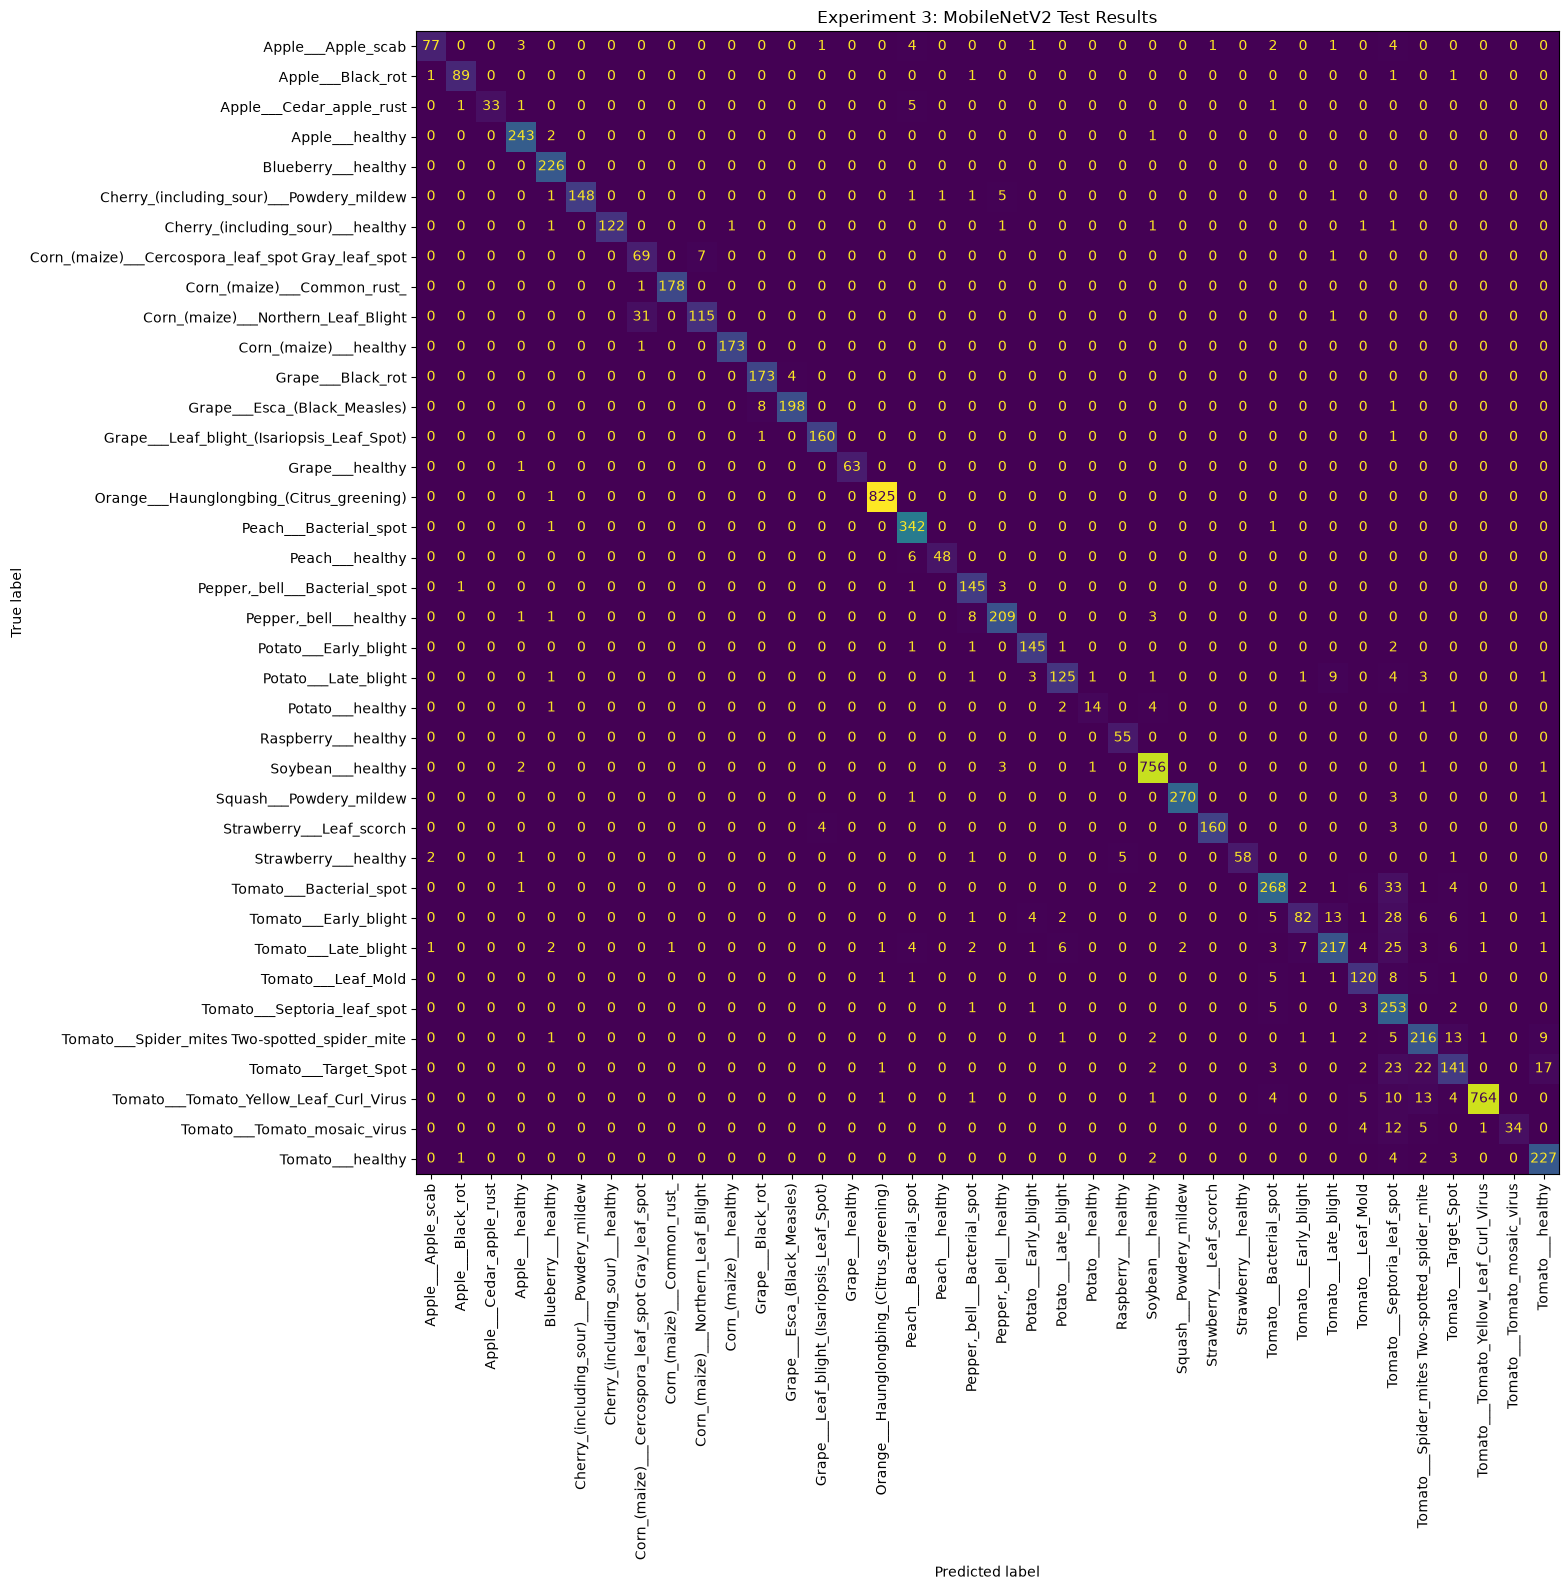


Results saved in: C:\PlantDiseaseProject\results


In [ ]:

# Step 14: Evaluate MobileNetV2 on the test dataset

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path(r"C:\PlantDiseaseProject")
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the saved model if it is not already in memory
if "model_transfer" not in globals():
    model_transfer = tf.keras.models.load_model(
        PROJECT_DIR / "models" / "plant_disease_mobilenetv2.keras"
    )


predictions = model_transfer.predict(test_ds, verbose=1)

y_pred = np.argmax(predictions, axis=1)

y_true = np.array([
    class_to_index[label] for label in test_labels
])

test_accuracy = accuracy_score(y_true, y_pred)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print("\nEXPERIMENT 3: MOBILENETV2")
print("-" * 40)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro precision: {report['macro avg']['precision'] * 100:.2f}%")
print(f"Macro recall: {report['macro avg']['recall'] * 100:.2f}%")
print(f"Macro F1-score: {report['macro avg']['f1-score'] * 100:.2f}%")
print(f"Weighted F1-score: {report['weighted avg']['f1-score'] * 100:.2f}%")

# Saving metrics
metrics = {
    "model": "MobileNetV2",
    "test_accuracy": float(test_accuracy),
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1_score": report["macro avg"]["f1-score"],
    "weighted_f1_score": report["weighted avg"]["f1-score"],
    "test_images": len(y_true),
    "number_of_classes": len(class_names)
}

with open(
    RESULTS_DIR / "experiment3_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metrics, file, indent=2)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(18, 16))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

plt.title("Experiment 3: MobileNetV2 Test Results")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion_matrix_mobilenetv2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nResults saved in:", RESULTS_DIR)


In [ ]:

# Step 15: Test MobileNetV2 on new phone photos

PROJECT_DIR = Path(r"C:\PlantDiseaseProject")

MODEL_PATH = PROJECT_DIR / "models" / "plant_disease_mobilenetv2.keras"
MAPPING_PATH = PROJECT_DIR / "results" / "class_mapping.json"

# Photos tested with the first CNN
photo_paths = [
    PROJECT_DIR / "test_photos" / "tomato_leaf.jpeg"
]
# Load your trained MobileNetV2 model
mobilenet_model = tf.keras.models.load_model(MODEL_PATH)

# Load class names in the correct output order
with open(MAPPING_PATH, "r", encoding="utf-8") as file:
    class_to_index = json.load(file)

class_names = [
    name for name, index in sorted(
        class_to_index.items(),
        key=lambda item: item[1]
    )
]

# Test each photo
for photo_path in photo_paths:

    print("\nPhoto:", photo_path.name)
    print("-" * 45)

    if not photo_path.is_file():
        print("Photo not found. Check its filename and folder.")
        continue

    # Resize and scale the photo 
    image = tf.keras.utils.load_img(
        photo_path,
        target_size=(150, 150)
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(image_array, axis=0)


    probabilities = mobilenet_model.predict(
        image_array, verbose=0
    )[0]

    top_indices = np.argsort(probabilities)[-3:][::-1]

    for index in top_indices:
        print(
            f"{class_names[index]}: "
            f"{probabilities[index] * 100:.2f}%"
        )

print("\nPhone-photo testing completed.")



Photo: tomato_leaf.jpeg
---------------------------------------------
Tomato___Bacterial_spot: 91.65%
Tomato___Septoria_leaf_spot: 4.31%
Peach___Bacterial_spot: 1.23%

Phone-photo testing completed.


In [ ]:

# Step 16: Test MobileNetV2 on all saved phone photos


PROJECT_DIR = Path(r"C:\PlantDiseaseProject")
PHOTO_DIR = PROJECT_DIR / "test_photos"


model = tf.keras.models.load_model(
    PROJECT_DIR / "models" / "plant_disease_mobilenetv2.keras"
)

# class mapping
with open(
    PROJECT_DIR / "results" / "class_mapping.json",
    "r",
    encoding="utf-8"
) as file:
    class_to_index = json.load(file)

class_names = [
    name for name, index in sorted(
        class_to_index.items(),
        key=lambda item: item[1]
    )
]

# Find saved photos
image_types = {".jpg", ".jpeg", ".png"}
photo_paths = sorted(
    path for path in PHOTO_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in image_types
)

if not photo_paths:
    print("No photos found in:", PHOTO_DIR)

for photo_path in photo_paths:
   
    image = tf.keras.utils.load_img(
        photo_path,
        target_size=(150, 150)
    )

    image_array = tf.keras.utils.img_to_array(image) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("\nPhoto:", photo_path.name)

    for index in top_indices:
        print(
            f"{class_names[index]}: "
            f"{probabilities[index] * 100:.2f}%"
        )



Photo: tomato_leaf.jpeg
Tomato___Bacterial_spot: 91.65%
Tomato___Septoria_leaf_spot: 4.31%
Peach___Bacterial_spot: 1.23%


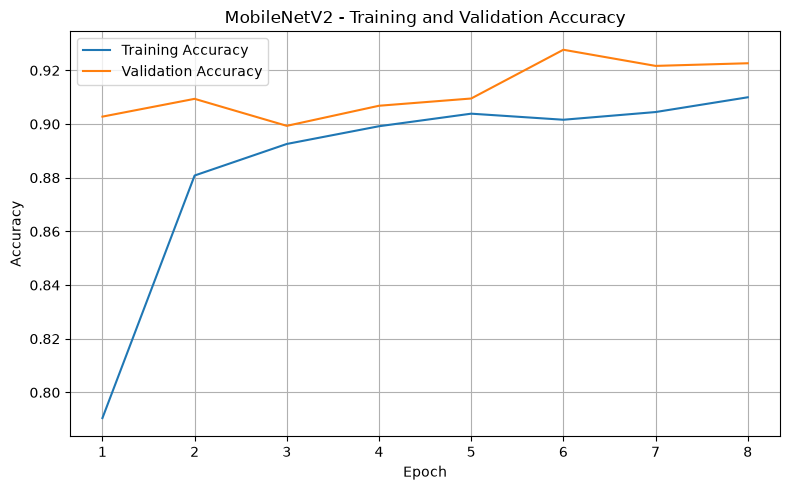

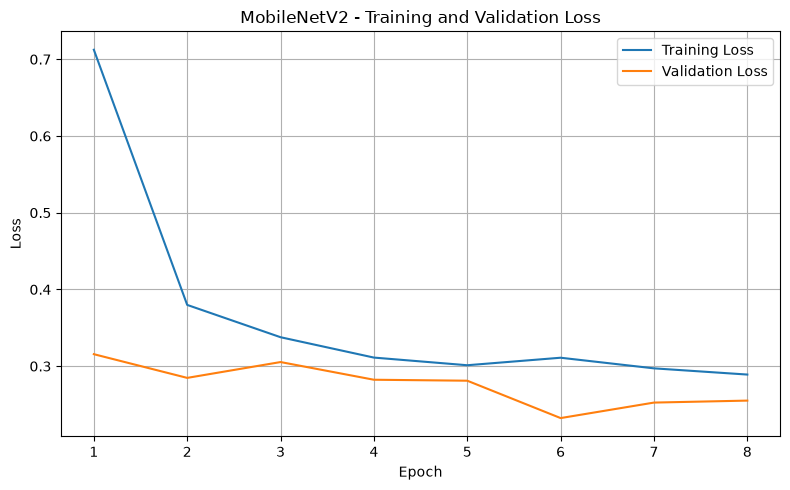

MobileNetV2 graphs saved successfully!
Results folder: C:\PlantDiseaseProject\results


In [ ]:

# Plot MobileNetV2 training curves

import matplotlib.pyplot as plt
import json
from pathlib import Path

results_dir = Path(r"C:\PlantDiseaseProject\results")
results_dir.mkdir(parents=True, exist_ok=True)

if "history_transfer" not in globals():
    raise RuntimeError(
        "Training history is unavailable. "
        "Do not retrain yet; let us check the saved training results."
    )

history_data = history_transfer.history

with open(
    results_dir / "mobilenetv2_training_history.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(history_data, file, indent=2)

epochs = range(1, len(history_data["accuracy"]) + 1)

# Graph 1: Accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, history_data["accuracy"],
         label="Training Accuracy")

plt.plot(epochs, history_data["val_accuracy"],
         label="Validation Accuracy")

plt.title("MobileNetV2 - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    results_dir / "mobilenetv2_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Graph 2: Loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, history_data["loss"],
         label="Training Loss")

plt.plot(epochs, history_data["val_loss"],
         label="Validation Loss")

plt.title("MobileNetV2 - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    results_dir / "mobilenetv2_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("MobileNetV2 graphs saved successfully!")
print("Results folder:", results_dir)


In [ ]:
from pathlib import Path

test_file = Path(
    r"C:\PlantDiseaseProject\results\dataset_split_seed42.csv"
)
if test_file.exists():
    print("Test split file found!")
else:
    print("Test split file not found.")

Test split file found!


In [2]:
import pandas as pd

csv_path = r"C:\PlantDiseaseProject\results\dataset_split_seed42.csv"

df = pd.read_csv(csv_path)

print(df.head())
print("\nColumns:")
print(df.columns.tolist())

print("\nImages in each split:")
print(df["split"].value_counts())

                                          image_path  \
0  C:\plantvillage dataset\color\Apple___Cedar_ap...   
1  C:\plantvillage dataset\color\Raspberry___heal...   
2  C:\plantvillage dataset\color\Tomato___Late_bl...   
3  C:\plantvillage dataset\color\Potato___Early_b...   
4  C:\plantvillage dataset\color\Corn_(maize)___h...   

                 class_name  label_id     split  
0  Apple___Cedar_apple_rust         2  training  
1       Raspberry___healthy        23  training  
2      Tomato___Late_blight        30  training  
3     Potato___Early_blight        20  training  
4    Corn_(maize)___healthy        10  training  

Columns:
['image_path', 'class_name', 'label_id', 'split']

Images in each split:
split
training      38013
validation     8146
testing        8146
Name: count, dtype: int64


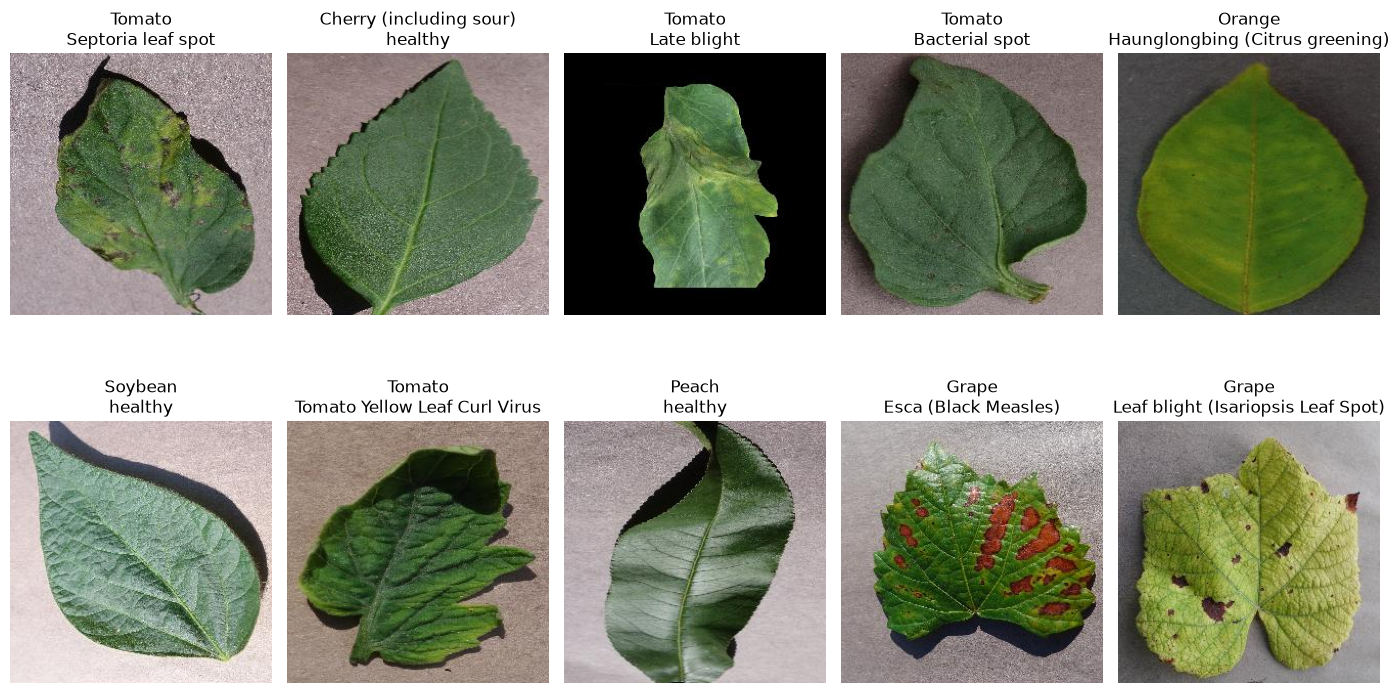

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

csv_path = r"C:\PlantDiseaseProject\results\dataset_split_seed42.csv"

df = pd.read_csv(csv_path)


test_images = df[df["split"] == "testing"]

#  10 random images
sample_images = test_images.sample(n=10, random_state=42)


plt.figure(figsize=(14, 8))

for i, (_, row) in enumerate(sample_images.iterrows()):

    image_path = Path(row["image_path"])

    if image_path.exists():
        image = Image.open(image_path).convert("RGB")

        plt.subplot(2, 5, i + 1)
        plt.imshow(image)
        plt.title(row["class_name"].replace("___", "\n").replace("_", " "))
        plt.axis("off")

    else:
        print("Image not found:", image_path)

plt.tight_layout()
plt.show()


In [ ]:

import shutil
from pathlib import Path

# Create a folder for testing images
output_folder = Path(r"C:\PlantDiseaseProject\test_samples")
output_folder.mkdir(exist_ok=True)

for i, (_, row) in enumerate(sample_images.iterrows(), start=1):

    source = Path(row["image_path"])

    if source.exists():
        class_name = row["class_name"]
        extension = source.suffix

        new_name = f"{i}_{class_name}{extension}"

        shutil.copy2(
            source,
            output_folder / new_name
        )

print("Test images saved successfully!")
print("Location:", output_folder)
print("Number of images:", len(list(output_folder.iterdir())))


Test images saved successfully!
Location: C:\PlantDiseaseProject\test_samples
Number of images: 10
